```mermaid
flowchart
A[Dimension Curse] --> B[Feature Selection]
A --> C[Feature Extraction]
B --> D[Forward Or Backward Selection]
C --> E[PCA, TSNA]
```

we are using mnist dataset which having 70k images each image in a hand drawn image of a number 0-9 and each image having 28*28  grid of pixel

means 784 pixels in a image

In [150]:
import numpy as np
import  pandas as pd
import seaborn as sns

In [151]:
try:
    df = pd.read_csv('digit-recognizer/train.csv',
                     index_col=False,
                     header=0,
                     engine='python',
                     on_bad_lines='skip',

                     )

except ImportError as e:
    print(e)




In [152]:
df.sample(10)

,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
26044,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
10046,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
23137,6,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
17865,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1203,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
39291,5,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
31070,6,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
20431,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4374,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
13317,6,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [153]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 42000 entries, 0 to 41999
Columns: 785 entries, label to pixel783
dtypes: int64(785)
memory usage: 251.5 MB


In [154]:
df.astype(int)

,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41995,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
41996,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
41997,7,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
41998,6,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [155]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 42000 entries, 0 to 41999
Columns: 785 entries, label to pixel783
dtypes: int64(785)
memory usage: 251.5 MB


In [156]:
num = df.iloc[3:4,1:]

In [157]:
num = np.reshape(num,(28,28))

<Axes: >

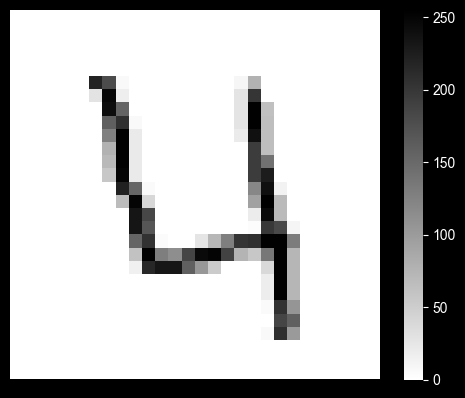

In [158]:
sns.heatmap(
    num,
    cmap="binary",
    square=True,
    cbar=True,  # Keeps the colorbar you had
    xticklabels=False,  # Hides the 784 pixel text labels at the bottom
    yticklabels=False,  # Hides the row index labels
)

In [159]:
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

In [160]:
x = df.iloc[:,1:]
y = df.iloc[:,0]

In [161]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)

In [162]:
knn = KNeighborsClassifier()
knn.fit(x_train,y_train)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [163]:
accuracy_score(y_test,knn.predict(x_test))

0.9648809523809524

Now we use PCA and try to get same accuracy but with less number of features or dim

In [164]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer


from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier


from sklearn.metrics import accuracy_score

In [165]:
x = df.iloc[:,1:]
y = df.iloc[:,0]
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)

In [166]:
x_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 33600 entries, 34941 to 15795
Columns: 784 entries, pixel0 to pixel783
dtypes: int64(784)
memory usage: 201.2 MB


In [167]:
x_train.sample(10)

,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
22555,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
6459,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
31961,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
38351,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
25955,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3188,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
34484,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
17793,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
25738,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
16532,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [168]:
x_train.columns

Index(['pixel0', 'pixel1', 'pixel2', 'pixel3', 'pixel4', 'pixel5', 'pixel6',
       'pixel7', 'pixel8', 'pixel9',
       ...
       'pixel774', 'pixel775', 'pixel776', 'pixel777', 'pixel778', 'pixel779',
       'pixel780', 'pixel781', 'pixel782', 'pixel783'],
      dtype='object', length=784)

First we  Do StandardScalling

pca depend upon varience so we need to arjust spread

In [169]:
num_pipeline = make_pipeline(
    StandardScaler(),
    PCA(n_components=500),
)

In [170]:
cr = ColumnTransformer(transformers=[
    ('num_pipeline', num_pipeline,x_train.columns),
])

In [171]:
eval = cr.fit_transform(x_test)

In [172]:
model = make_pipeline(
    cr,
    KNeighborsClassifier(),
)

In [173]:
model.fit(x_train,y_train)

,steps,"[('columntransformer', ...), ('kneighborsclassifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num_pipeline', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [174]:
x_test_trf = pd.DataFrame(eval, columns=cr.get_feature_names_out(),index=x_test.index)

In [175]:
y_test_trf = pd.DataFrame(y_test)

In [176]:
y_test_trf

,label
5457,8
38509,1
25536,9
31803,9
39863,8
...,...
8388,4
29359,9
40276,3
18421,0


In [177]:
x = pd.concat([y_test_trf,x_test_trf],axis=1)

In [178]:
import plotly.express as px

y_test_trf = y_test.astype(str)

fig = px.scatter_3d(
    x,
    x=x.columns[1],
    y=x.columns[2],
    z=x.columns[3],
    color='label',
    opacity=0.8
)

fig.update_traces(
    marker=dict(size=3)
)

fig.update_layout(
    title='PCA 3D Visualization',
    scene=dict(
        xaxis_title='PC1',
        yaxis_title='PC2',
        zaxis_title='PC3'
    ),
    margin=dict(l=0, r=0, t=40, b=0)
)

fig.show()

Now we need to find best value of n where n is number of dim or PC

In [179]:
model.named_steps
model.named_steps['columntransformer'].named_transformers_
pca = model.named_steps['columntransformer'].named_transformers_['num_pipeline'].named_steps['pca']

In [180]:
x = np.cumsum(pca.explained_variance_ratio_)*100

<Axes: >

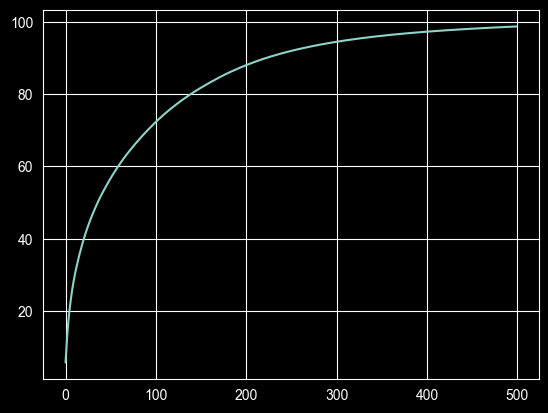

In [181]:
sns.lineplot(data=x)